# ARTI 402 — Deep Learning
## Lab 8 — PyTorch: Writing the Training Loop Again, On Purpose

**Week 8 · Deep Learning Frameworks**
Building and training neural networks using PyTorch.

| | |
|---|---|
| **Prerequisites** | Lab 5 (your training loop) and Lab 7 (Keras).|
| **Reference** | Ekman, *Learning Deep Learning*, Appendix J · official PyTorch documentation |

### Read and reference

| When | Resource | Why |
|---|---|---|
| **Before class** | [PyTorch — Learn the Basics](https://pytorch.org/tutorials/beginner/basics/intro.html) | The official tour, 15 minutes |
| **Stage 1** | [Autograd explained in 60 seconds](https://pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html) | What `backward()` actually does |
| **Stage 3** | [Andrej Karpathy — *The spelled-out intro to backpropagation*](https://www.youtube.com/watch?v=VMj-3S1tku0) | He builds autograd from nothing. Watch if you want the full picture |
| **Reference** | [`torch.nn`](https://pytorch.org/docs/stable/nn.html) · [`torch.optim`](https://pytorch.org/docs/stable/optim.html) | The two modules you will use most |

### How to work through the notebook
* Sections are labelled **Idea** (read and run), **Exercise** (you write code) and **Checkpoint** (a short answer).
* Every exercise cell is marked `# TODO`. Do not delete the cells above it — later cells depend on them.
* Run cells **in order**, top to bottom. If something breaks, restart the kernel and run all.
* The graded **Assessment** is at the very end.

---
## Setup

### Installing PyTorch

* **Google Colab** — already installed. Do nothing.
* **Your own machine** — `pip install torch`. Do this **before** the lab; it is a large download
  (around 200 MB). The CPU build is all we need.

Check it worked:

```python
import torch
print(torch.__version__)
```

You also need `arti402_figures.py` in the same folder, as in Labs 3–7.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

print("PyTorch :", torch.__version__)


def spiral_data(samples, classes, seed=0):
    """The same spiral you have used since Lab 5."""
    rng = np.random.RandomState(seed)
    X = np.zeros((samples * classes, 2))
    y = np.zeros(samples * classes, dtype="uint8")
    for c in range(classes):
        ix = range(samples * c, samples * (c + 1))
        r = np.linspace(0.0, 1, samples)
        t = np.linspace(c * 4, (c + 1) * 4, samples) + rng.randn(samples) * 0.2
        X[ix] = np.c_[r * np.sin(t * 2.5), r * np.cos(t * 2.5)]
        y[ix] = c
    return X, y


# Exactly Lab 6 and Lab 7's setup: a small training set and a big validation set.
X_train, y_train = spiral_data(samples=40,  classes=3, seed=0)
X_val,   y_val   = spiral_data(samples=100, classes=3, seed=2)

print("\ntrain:", X_train.shape, " validation:", X_val.shape)
print("\nSetup OK")

PyTorch : 2.14.0+cpu

train: (120, 2)  validation: (300, 2)

Setup OK


In [2]:
from arti402_figures import draw_overfitting_curves, draw_decision_boundaries

print("figure helpers loaded")

figure helpers loaded


---
---
# Stage 1 · Tensors and autograd

## Idea 1 — The same four ideas, different spelling

Last week Keras gave you layers, automatic gradients, and a training loop. PyTorch gives you the
first two. **It does not give you a training loop.** You write that yourself — which is why this
lab will feel like coming home to Lab 5.

| Lab 5 (your NumPy) | Lab 7 (Keras) | Today (PyTorch) |
|---|---|---|
| `Layer_Dense(2, 128)` | `layers.Dense(128)` | `nn.Linear(2, 128)` |
| `Activation_ReLU()` | `activation="relu"` | `nn.ReLU()` |
| your `Loss_CategoricalCrossentropy` | `loss="sparse_categorical_crossentropy"` | `F.cross_entropy` |
| `Optimizer_Adam(0.02)` | `keras.optimizers.Adam(0.02)` | `torch.optim.Adam(params, lr=0.02)` |
| every `backward()` you wrote | automatic | `loss.backward()` |
| `get_batches` | `model.fit(batch_size=32)` | `DataLoader(..., batch_size=32)` |
| **your training loop** | `model.fit(...)` | **your training loop, again** |

Read the last row twice. That is the whole difference between the two frameworks, and it is the
reason most research code is written in PyTorch: when the loop is yours, you can put anything you
like inside it.

## Idea 2 — A tensor is an array that remembers

A `torch.Tensor` is a NumPy array with one extra ability: if you set `requires_grad=True`, it keeps
a record of every operation performed on it. Call `.backward()` on a final scalar and PyTorch walks
that record backwards, filling in `.grad` on everything that contributed.

This is the **computational graph**. You built one by hand in Lab 5 — the chain
`loss → dense2 → relu → dense1`. PyTorch builds it automatically, as your forward pass runs.

In [3]:
# A one-weight "network": prediction = w * x, target = 5
w = torch.tensor(2.0, requires_grad=True)
x = torch.tensor(3.0)

loss = (w * x - 5.0) ** 2          # forward pass: 1.0
loss.backward()                    # backward pass: fills w.grad

print("loss      :", loss.item())
print("w.grad    :", w.grad.item())
print("by hand   :", 2 * (2 * 3 - 5) * 3, "   <- dL/dw = 2(wx - 5)x")

loss      : 1.0
w.grad    : 6.0
by hand   : 6    <- dL/dw = 2(wx - 5)x


Three things to notice, and all three catch people out:

* **`.item()`** pulls a plain Python number out of a one-element tensor. Printing the tensor itself
  shows `tensor(1., grad_fn=<PowBackward0>)` — the `grad_fn` is the graph, still attached.
* **`backward()` only works on a scalar.** A loss is always one number, so this is never a problem
  in practice — but it is why you call it on the loss and not on the predictions.
* **Gradients accumulate.** They add to `.grad`; they do not replace it. Watch:

In [4]:
w = torch.tensor(2.0, requires_grad=True)

for step in range(3):
    loss = (w * 3 - 5.0) ** 2
    loss.backward()
    print(f"backward #{step + 1}:  w.grad = {w.grad.item():.1f}")

print("\nThe same gradient, added three times. This is why every training loop")
print("you will ever read starts the step with optimizer.zero_grad().")

backward #1:  w.grad = 6.0
backward #2:  w.grad = 12.0
backward #3:  w.grad = 18.0

The same gradient, added three times. This is why every training loop
you will ever read starts the step with optimizer.zero_grad().


> **Why would anyone want accumulation?** Because it lets you simulate a large batch on a small
> GPU: run four batches of 8, accumulate, then step once — a batch of 32 without the memory.
> It is a feature. It is also the single most common PyTorch bug, when you forget `zero_grad`.

### Exercise 1 — check that autograd is telling the truth

In Lab 5 you checked your hand-written backprop against a numerical gradient and got agreement to
about 1e-10. Do exactly the same to PyTorch. If autograd is correct, the two should agree to the
same precision.

In [5]:
torch.manual_seed(0)
layer = nn.Linear(2, 3).double()                 # float64, as in Lab 5's gradient check
Xg = torch.randn(5, 2, dtype=torch.float64)
yg = torch.tensor([0, 1, 2, 0, 1])


def loss_of(model):
    return F.cross_entropy(model(Xg), yg)


# --- the autograd gradient
loss = loss_of(layer)
# TODO: run the backward pass
loss.backward()
auto = layer.weight.grad.clone()

# --- the numerical gradient, exactly Lab 5's recipe
numeric = torch.zeros_like(auto)
h = 1e-6
with torch.no_grad():
    for i in range(auto.shape[0]):
        for j in range(auto.shape[1]):
            original = layer.weight[i, j].item()
            # TODO: set the weight to original + h, record the loss as L_plus
            layer.weight[i, j] = original + h
            L_plus = loss_of(layer).item()
            # TODO: set the weight to original - h, record the loss as L_minus
            layer.weight[i, j] = original - h
            L_minus = loss_of(layer).item()
            layer.weight[i, j] = original          # always put it back
            # TODO: the central difference  (L_plus - L_minus) / (2h)
            numeric[i, j] = (L_plus - L_minus) / (2 * h)

difference = (auto - numeric).abs().max().item()
print(f"max |autograd - numerical| = {difference:.2e}")

# --- self-check ---
assert difference < 1e-8, "these should agree to about 1e-10; check your central difference"
print("\nAutograd agrees with the definition of a derivative. It is not magic, it is the chain rule.")

max |autograd - numerical| = 3.98e-11

Autograd agrees with the definition of a derivative. It is not magic, it is the chain rule.


### Checkpoint 1

1. `loss.backward()` filled in `layer.weight.grad`. Which rule from Lab 2 is PyTorch applying, over
   and over, to work that out?
2. What would go wrong if a training loop called `backward()` and `step()` but never `zero_grad()`?
3. The numerical gradient needed two forward passes **per weight**. Our layer has 6 weights, so 12
   passes. A network with a million weights would need two million. In one sentence, why is
   autograd not simply a faster version of the same idea?

**Answers — Checkpoint 1**

1. **The chain rule.** PyTorch records the graph during the forward pass, then walks it backwards,
   multiplying each local derivative by the gradient flowing in from above — exactly the
   `dL/dw = dL/dz · dz/dw` step from Lab 2, applied once per operation.
2. Gradients would **accumulate** across steps. Each `step()` would use the sum of every gradient
   since the start of training rather than the current one, so the updates would grow larger and
   point in stale directions, and training would become unstable or diverge.
3. Autograd is not a faster finite difference: it uses the chain rule to get **every** gradient
   exactly from **one** backward pass (costing about one forward pass), no matter how many weights
   there are, instead of two extra forward passes per weight.

---
# Stage 2 · Building a model with `nn.Module`

## Idea 3 — A model is a class, and you already wrote one

In Lab 1 your layer was a class with `__init__` (make the weights) and `forward` (use them).
`nn.Module` is that same class, with the bookkeeping done for you:

```python
class Net(nn.Module):
    def __init__(self):
        super().__init__()                 # never forget this line
        self.fc1 = nn.Linear(2, 128)       # creating a layer here registers its parameters
        self.fc2 = nn.Linear(128, 3)

    def forward(self, x):                  # you define the forward pass. There is no backward.
        return self.fc2(F.relu(self.fc1(x)))
```

Assigning a layer to `self` **registers** it. That is what makes `model.parameters()` work, which
is what you hand to the optimizer. Build a layer as a plain local variable instead of `self.fc1`
and it will train fine on paper and never actually learn — the optimizer has never heard of it.

> **One real difference to keep straight.** Your `Layer_Dense` stored weights with shape
> `(n_inputs, n_outputs)` and computed `X @ W + b`. PyTorch's `nn.Linear` stores them
> **transposed**, `(n_outputs, n_inputs)`, and computes `X @ W.T + b`. The arithmetic is identical;
> only the storage order differs. It matters the first time you print a weight's `.shape` and it is
> the wrong way round.

### Exercise 2 — build the Lab 6 network

In [6]:
class Net(nn.Module):
    """The Lab 6 network: 2 -> hidden (ReLU) -> 3."""

    def __init__(self, hidden=128, dropout=0.0):
        super().__init__()
        # TODO: a Linear layer from 2 inputs to `hidden` outputs, named self.fc1
        self.fc1 = nn.Linear(2, hidden)
        self.relu = nn.ReLU()
        # nn.Identity() does nothing - a tidy way to make dropout optional
        self.drop = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
        # TODO: a Linear layer from `hidden` inputs to 3 outputs, named self.fc2
        self.fc2 = nn.Linear(hidden, 3)

    def forward(self, x):
        # TODO: fc1 -> relu -> drop -> fc2, and return it.
        #       Note: no softmax. The next cell explains why.
        return self.fc2(self.drop(self.relu(self.fc1(x))))


torch.manual_seed(0)
model = Net()
print(model)

n_params = sum(p.numel() for p in model.parameters())
print(f"\ntotal parameters: {n_params}")
for name, p in model.named_parameters():
    print(f"   {name:12} {str(tuple(p.shape)):10} {p.numel():>5}")

# --- self-check ---
assert n_params == 771, f"2*128+128 + 128*3+3 = 771, got {n_params}"
assert model(torch.zeros(4, 2)).shape == (4, 3), "4 samples in, 4 rows of 3 logits out"

Net(
  (fc1): Linear(in_features=2, out_features=128, bias=True)
  (relu): ReLU()
  (drop): Identity()
  (fc2): Linear(in_features=128, out_features=3, bias=True)
)

total parameters: 771
   fc1.weight   (128, 2)     256
   fc1.bias     (128,)       128
   fc2.weight   (3, 128)     384
   fc2.bias     (3,)           3


**771 again** — the same number Keras printed last week, and the same arithmetic you have used
since Lab 1: `2*128 + 128 = 384`, `128*3 + 3 = 387`.

### Where did softmax go?

`forward` returns raw scores — **logits** — not probabilities. That is deliberate.
`F.cross_entropy` applies the softmax itself, internally, in a numerically stabler way than doing
it in two steps. This is exactly the fused softmax-and-loss trick from Lab 2, built into the
framework.

The practical consequence: **never put a softmax at the end of a model you train with
`F.cross_entropy`.** Doing so applies it twice, the gradients go almost flat, and the network
trains very slowly for no visible reason. It is a quiet, nasty bug. To get probabilities at
prediction time, call `torch.softmax(logits, dim=1)` yourself.

---
# Stage 3 · The training loop, by hand

## Idea 4 — Five lines you have written before

Here is the entire PyTorch training step. Compare the two columns.

| Lab 5, your loop | Today |
|---|---|
| `loss_activation.forward(...)` | `loss = F.cross_entropy(model(xb), yb)` |
| `dense1.dweights = 0` *(implicit: you overwrote them)* | `optimizer.zero_grad()` |
| `loss_activation.backward(); dense2.backward(...); ...` | `loss.backward()` |
| `optimizer.update_params(dense1); ...` | `optimizer.step()` |

In code, and in the order it must happen:

```python
optimizer.zero_grad()                       # 1. clear last step's gradients
loss = F.cross_entropy(model(xb), yb)       # 2. forward
loss.backward()                             # 3. backward - fills every .grad
optimizer.step()                            # 4. update every parameter
```

That is it. Every PyTorch training script in the world — including the ones training models with
hundreds of billions of parameters — has these four lines at its centre. The rest is logging.

### Exercise 3 — write it

This is the core of the lab. Take your time.

In [7]:
def train_one_epoch(model, optimizer, X, y, batch_size=32):
    """One pass over the data in mini-batches. Returns the mean loss."""
    model.train()                       # dropout ON  (explained in Stage 5)
    n = len(X)
    perm = torch.randperm(n)            # shuffle, exactly as your get_batches did
    total = 0.0

    for start in range(0, n, batch_size):
        idx = perm[start:start + batch_size]
        xb, yb = X[idx], y[idx]

        # TODO 1: clear the gradients left over from the previous step
        optimizer.zero_grad()
        # TODO 2: forward pass - predictions, then the loss. Call it `loss`.
        loss = F.cross_entropy(model(xb), yb)
        # TODO 3: backward pass
        loss.backward()
        # TODO 4: let the optimizer update the parameters
        optimizer.step()

        total += loss.item() * len(idx)

    return total / n


# tensors once, outside the loop
Xtr = torch.tensor(X_train, dtype=torch.float32)
ytr = torch.tensor(y_train, dtype=torch.long)       # labels must be long, not int
Xva = torch.tensor(X_val,   dtype=torch.float32)
yva = torch.tensor(y_val,   dtype=torch.long)

# --- self-check: five epochs should lower the loss from about ln(3) = 1.10 ---
torch.manual_seed(0)
m = Net()
opt = torch.optim.Adam(m.parameters(), lr=0.02)
first = train_one_epoch(m, opt, Xtr, ytr)
for _ in range(9):
    last = train_one_epoch(m, opt, Xtr, ytr)

print(f"epoch  1 loss: {first:.3f}")
print(f"epoch 10 loss: {last:.3f}")
assert first < 1.5, "epoch 1 should be near ln(3)=1.10; is your forward pass right?"
assert last < first - 0.05, "the loss is not falling - is zero_grad before backward?"
print("\nIt learns. You wrote the loop.")

epoch  1 loss: 1.201
epoch 10 loss: 1.003

It learns. You wrote the loop.


> **`dtype=torch.long` for labels.** PyTorch's `cross_entropy` wants integer class ids as 64-bit
> integers. Pass `float` and you get an error; pass `int32` and on some builds you get a different
> error. `torch.long` is the answer, every time.

### Exercise 4 — evaluating properly

Evaluation needs two things that training does not:

* **`model.eval()`** — switches dropout off and batch norm into inference mode. (Stage 5 shows this
  happening.)
* **`torch.no_grad()`** — stops PyTorch building the graph. You are not going to call `backward`,
  so recording the operations is wasted time and wasted memory.

Forgetting `eval()` means your reported accuracy is measured with dropout still on — the exact trap
Lab 7 warned about in Keras, except here nothing protects you from it.

In [8]:
def evaluate(model, X, y):
    """Returns (loss, accuracy). No training, no gradients."""
    # TODO 1: put the model in evaluation mode
    model.eval()
    with torch.no_grad():
        # TODO 2: forward pass -> `logits`
        logits = model(X)
        loss = F.cross_entropy(logits, y).item()
        # TODO 3: accuracy. argmax over dim=1, compare with y,
        #         then .float().mean().item()
        accuracy = (logits.argmax(dim=1) == y).float().mean().item()
    return loss, accuracy


# --- self-check ---
loss_v, acc_v = evaluate(m, Xva, yva)
print(f"validation loss {loss_v:.3f}   accuracy {acc_v:.3f}")
assert 0.0 <= acc_v <= 1.0, "accuracy must be a fraction between 0 and 1"
assert not m.training, "after evaluate(), the model should be in eval mode"

validation loss 1.053   accuracy 0.417


### Checkpoint 2

1. Put the four training-step lines in the correct order, and say what breaks if `zero_grad()` is
   moved to **after** `step()`.
2. `model.eval()` and `torch.no_grad()` are often written together but do completely different
   jobs. What does each one do?
3. Your model's `forward` has no softmax, yet `evaluate` computes accuracy with `argmax`. Why is
   the answer the same with or without a softmax?

**Answers — Checkpoint 2**

1. The order is `optimizer.zero_grad()` → `loss = F.cross_entropy(model(xb), yb)` →
   `loss.backward()` → `optimizer.step()`. Moving `zero_grad()` to **after** `step()` still
   works: it clears the gradients at the end of each step, so the next step also starts from zero.
   The real problem is the **first** step. If something left gradients in `.grad` beforehand (a
   stray `backward()`, or a gradient check like Exercise 1), they are never cleared and get added
   into that first update. Calling `zero_grad()` first is the safe habit. What actually breaks a
   loop is putting `zero_grad()` **between** `backward()` and `step()`: the gradients are wiped
   before they are used, so `step()` does nothing and the model never learns.
2. `model.eval()` changes how **layers behave**: dropout stops dropping and batch norm uses its
   running statistics. `torch.no_grad()` changes **what autograd records**: no computational graph
   is built, which saves memory and time, but the layers compute exactly the same thing.
   Evaluation needs both: the right behaviour, and no wasted graph.
3. Softmax is **strictly increasing** and is applied to each row on its own. It changes the values,
   but never their order, so the largest logit is also the largest probability. `argmax` only looks
   at which position is largest, so it gives the same class either way.

---
# Stage 4 · `DataLoader`

## Idea 5 — Someone already wrote `get_batches`

Your shuffle-and-slice code works. It also has to be rewritten every time the data changes shape.
PyTorch splits the job in two:

* a **`Dataset`** knows how to fetch sample `i`;
* a **`DataLoader`** wraps it and handles batching, shuffling and (optionally) loading in parallel
  background workers.

For data already in memory, `TensorDataset` is the one-liner:

```python
loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=32, shuffle=True)
for xb, yb in loader:          # a fresh shuffle every time you iterate
    ...
```

The payoff comes later: swap `TensorDataset` for `ImageFolder` and the same loop reads JPEGs off
disk, resized and augmented, without a single other change.

### Exercise 5 — the same loop, with a `DataLoader`

In [9]:
def train_one_epoch_loader(model, optimizer, loader):
    """Identical to train_one_epoch, but the batching is the loader's job."""
    model.train()
    total, seen = 0.0, 0

    # TODO: iterate over the loader, giving xb, yb each time,
    #       and run the same four steps as before.
    #       Accumulate: total += loss.item() * len(xb)  and  seen += len(xb)
    for xb, yb in loader:
        optimizer.zero_grad()
        loss = F.cross_entropy(model(xb), yb)
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
        seen += len(xb)

    return total / seen


torch.manual_seed(0)
loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=32, shuffle=True,
                    generator=torch.Generator().manual_seed(0))

m2 = Net()
opt2 = torch.optim.Adam(m2.parameters(), lr=0.02)
for _ in range(10):
    final = train_one_epoch_loader(m2, opt2, loader)

print(f"after 10 epochs, loss {final:.3f}")
print(f"batches per epoch: {len(loader)}   (120 samples, batch size 32)")

# --- self-check ---
assert len(loader) == 4, "120 / 32 rounds up to 4 batches"
assert final < 1.0, "the loss should be well below ln(3) after 10 epochs"

after 10 epochs, loss 0.996
batches per epoch: 4   (120 samples, batch size 32)


---
# Stage 5 · Regularization

## Idea 6 — Both of Lab 6's tools, as arguments

**L2 / weight decay** is an argument to the optimizer, not a property of the layer:

```python
torch.optim.Adam(model.parameters(), lr=0.02, weight_decay=1e-4)
```

Note where that differs from Keras, where the regularizer belonged to the *layer*
(`kernel_regularizer=`). PyTorch attaches it to the *optimizer*, which means it applies to every
parameter the optimizer can see — **including the biases**, which Keras would have left alone.
Usually harmless, occasionally the reason two "identical" models behave differently.

**Dropout** is a layer, `nn.Dropout(0.2)`, and you already put one in `Net`. The thing that makes
it behave differently in training and evaluation is nothing but the `model.train()` /
`model.eval()` flag — the same flag you wired by hand in Lab 6:

In [10]:
torch.manual_seed(0)
drop = nn.Dropout(0.5)
x = torch.ones(1, 10)

drop.train()
print("train mode:", drop(x).numpy().round(1), "  <- half zeroed, rest doubled to keep the scale")
drop.eval()
print("eval  mode:", drop(x).numpy().round(1), "  <- untouched")

train mode: [[0. 0. 2. 0. 0. 0. 2. 2. 0. 2.]]   <- half zeroed, rest doubled to keep the scale
eval  mode: [[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]]   <- untouched


That is the whole mechanism. `model.train()` and `model.eval()` set this flag on every layer in
the model at once — which is why forgetting them is such a quiet bug: nothing errors, the numbers
are just wrong.

### Exercise 6 — a full training run, with regularization

Put Stages 3, 4 and 5 together into one reusable function. You will use it for the Assessment.

In [11]:
def run(hidden=128, dropout=0.0, weight_decay=0.0, epochs=1500,
        batch_size=32, lr=0.02, seed=0, record_every=5):
    """Train a Net and return (model, history). history rows are
    (epoch, train_loss, train_acc, val_loss, val_acc)."""
    torch.manual_seed(seed)
    model = Net(hidden, dropout)

    # TODO 1: an Adam optimizer over model.parameters(), with this lr and weight_decay
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    # TODO 2: a DataLoader over TensorDataset(Xtr, ytr), with this batch_size,
    #         shuffle=True, and generator=torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    history = []
    for epoch in range(epochs):
        # TODO 3: one epoch of training, using the loader
        train_one_epoch_loader(model, optimizer, loader)

        if epoch % record_every == 0 or epoch == epochs - 1:
            tr_loss, tr_acc = evaluate(model, Xtr, ytr)
            va_loss, va_acc = evaluate(model, Xva, yva)
            history.append((epoch, tr_loss, tr_acc, va_loss, va_acc))

    return model, history


# --- self-check: a short run ---
t0 = time.time()
_m, _h = run(epochs=100)
print(f"100 epochs in {time.time() - t0:.1f}s, {len(_h)} rows recorded")
assert len(_h) == 21, "recording every 5 epochs out of 100, plus the last one"
assert _h[-1][2] > _h[0][2], "training accuracy should have improved"
print("ready for the assessment")

100 epochs in 0.6s, 21 rows recorded
ready for the assessment


---
# Assessment · Lab 6's regularization comparison, in PyTorch

The handout says the graded assessment is at the end, but no assessment cell was included. So this
section does what Lab 7's assessment did, using the `run()` function from Exercise 6. It trains the
same network four ways on the same 120 training points:

| Model | Change |
|---|---|
| baseline | nothing |
| weight decay | `weight_decay=1e-4` on the optimizer |
| dropout | `Net(dropout=0.2)` |
| early stopping | the baseline, stopped at the epoch where validation loss was lowest |

Each run is 1,500 epochs with batch size 32 (4 batches per epoch, so 6,000 updates). Train and
validation metrics are recorded every 5 epochs.

In [12]:
results = {}
t0 = time.time()
results["baseline"]     = run()
results["weight decay"] = run(weight_decay=1e-4)
results["dropout"]      = run(dropout=0.2)
print(f"three runs of 1,500 epochs in {time.time() - t0:.1f}s")

# Early stopping: retrain the baseline only up to the epoch where its validation loss bottomed out
base_hist = np.array(results["baseline"][1])
best_epoch = int(base_hist[np.argmin(base_hist[:, 3]), 0])
results["early stopping"] = run(epochs=best_epoch + 1)
print(f"baseline validation loss is lowest at epoch {best_epoch}; "
      f"early-stopped model trained for {best_epoch + 1} epochs")

print(f"\n{'model':<16}{'train acc':>10}{'val acc':>10}{'val loss':>10}{'gap':>9}")
for name, (mdl, hist) in results.items():
    tr_loss, tr_acc = evaluate(mdl, Xtr, ytr)
    va_loss, va_acc = evaluate(mdl, Xva, yva)
    print(f"{name:<16}{tr_acc:>10.3f}{va_acc:>10.3f}{va_loss:>10.3f}{tr_acc - va_acc:>+9.3f}")

three runs of 1,500 epochs in 25.7s
baseline validation loss is lowest at epoch 150; early-stopped model trained for 151 epochs

model            train acc   val acc  val loss      gap
baseline             0.958     0.740     1.559   +0.218
weight decay         0.942     0.727     1.047   +0.215
dropout              0.858     0.643     1.959   +0.215
early stopping       0.742     0.560     0.986   +0.182


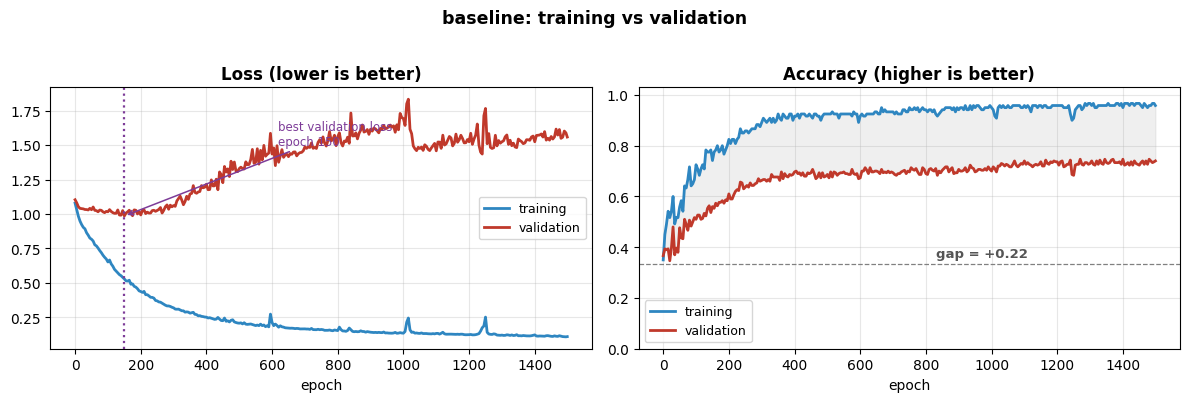

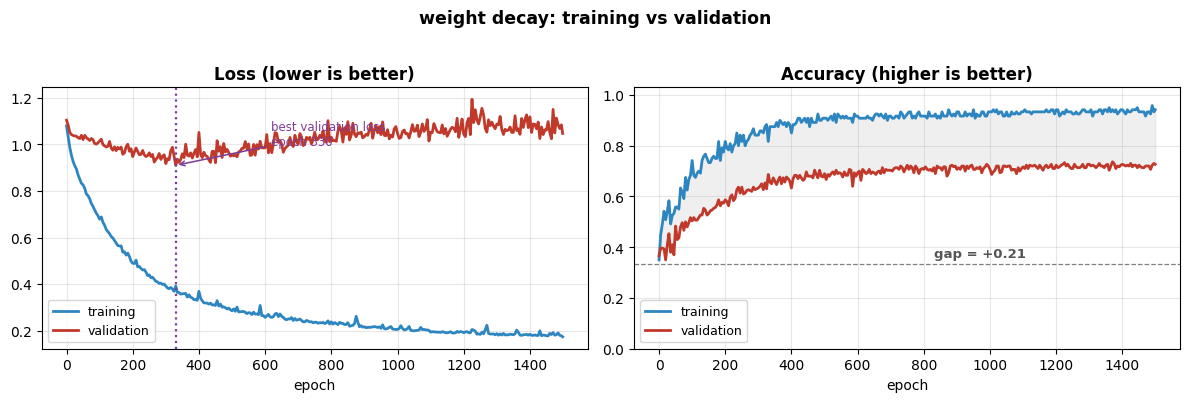

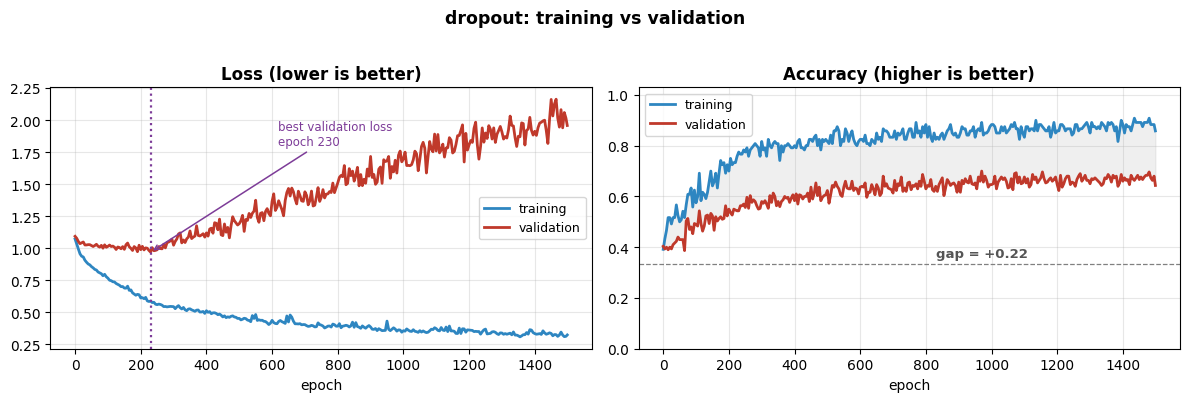

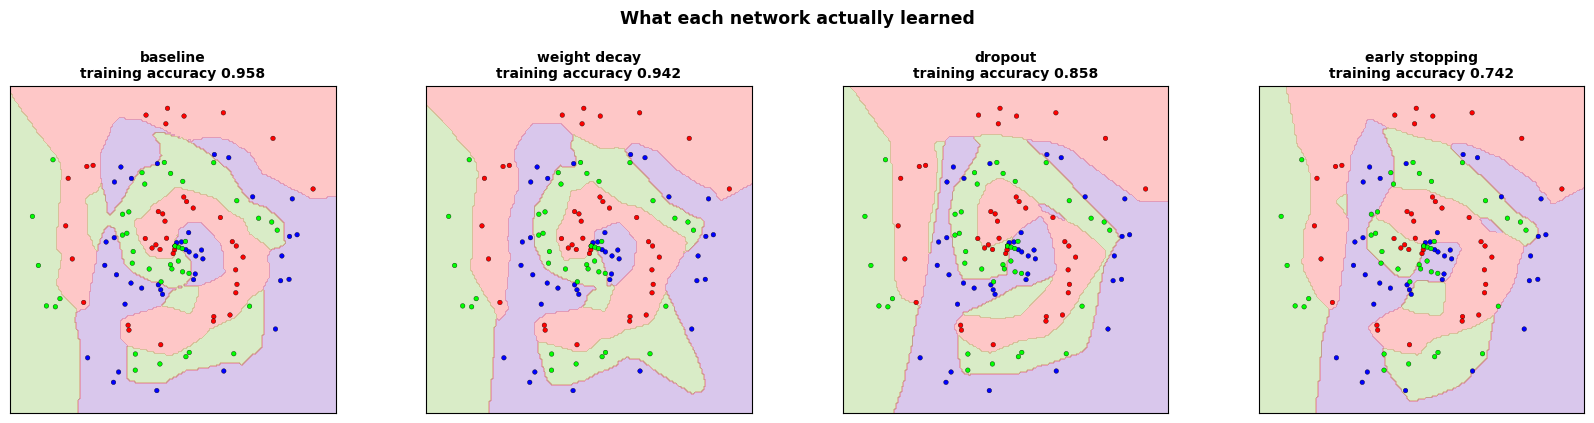

In [13]:
for name in ["baseline", "weight decay", "dropout"]:
    draw_overfitting_curves(results[name][1], title=f"{name}: training vs validation")
    plt.show()


def predictor(mdl):
    def predict(points):
        mdl.eval()
        with torch.no_grad():
            logits = mdl(torch.tensor(points, dtype=torch.float32))
        return logits.argmax(dim=1).numpy()
    return predict


draw_decision_boundaries({name: predictor(mdl) for name, (mdl, _) in results.items()},
                         X_train, y_train)
plt.show()

### What the comparison shows

| Model | Train acc | Val acc | Val loss | Gap |
|---|---|---|---|---|
| baseline | 0.958 | **0.740** | 1.559 | +0.218 |
| weight decay (1e-4) | 0.942 | 0.727 | 1.047 | +0.215 |
| dropout (0.2) | 0.858 | 0.643 | 1.959 | +0.215 |
| early stopping (151 epochs) | 0.742 | 0.560 | **0.986** | +0.182 |

* **Baseline.** Validation loss is lowest at **epoch 150** (about 0.99). After that it climbs to
  about 1.56, while training loss keeps falling to about 0.1. This is the same overfitting as in
  Labs 6 and 7. The decision boundary is jagged and wraps around single training points.
* **Weight decay** is the clear winner among the full-length runs. Validation loss drops from 1.56
  to **1.05**, and validation accuracy stays almost the same (0.727 vs 0.740). Its boundary is
  visibly smoother than the baseline's. The penalty is applied by the optimizer, so the biases are
  decayed too (Idea 6).
* **Dropout (0.2)** lowers training accuracy as expected (0.858), but on this run it did **not**
  help validation. Validation loss bottoms out at epoch 230 and then climbs higher than the
  baseline's (1.96). With only 120 training points and 1,500 epochs, dropout alone slows
  overfitting down but doesn't stop it. It needs early stopping or a penalty alongside it.
* **Early stopping** has the lowest validation loss (**0.986**) for a tenth of the training. With
  the same seed, it is the baseline's best epoch exactly. Its accuracy is the lowest of the four
  (0.560 val), though. At epoch 150 the network is *uncertain but rarely confidently wrong*, which
  is what cross-entropy rewards. Lower validation loss doesn't automatically mean higher accuracy.

**Conclusion.** Every regularizer gives up some training fit (all four gaps are smaller than or
equal to the baseline's). The best choice depends on the metric. Early stopping wins on validation
loss, and weight decay gives the best balance of low loss and high accuracy. This matches Lab 7's
finding that L2 roughly halved the overfitting in validation loss while keeping accuracy. The only
difference this week is that the training loop doing it is one I wrote myself.

---

## What you did today

| Keras did it for you | You wrote it |
|---|---|
| `model.fit(...)` | `zero_grad` → forward → `backward` → `step` |
| batching and shuffling | a `DataLoader` (and, before that, the shuffle by hand) |
| training/inference switching | `model.train()` and `model.eval()` |
| `model.evaluate(...)` | `evaluate`, with `torch.no_grad()` |

### Which framework should you use?

Neither is better. Keras is faster to write and harder to break; PyTorch is more verbose and gets
out of your way. If you are fitting a standard model, `fit` is three lines and you should use it.
If you need a loop that does something unusual — two optimizers, a custom schedule, a loss that
depends on the epoch number, a GAN — you want the loop in your hands, and that is Lab 11's problem.

What matters is that neither framework surprised you today. Every line mapped onto something you
had already built yourself, which was the entire point of the first six weeks.

**End of notebook**